# Fine-Tuning Model CLIP pada Dataset Baru: DORMIY E-Commerce

Notebook ini melatih model **OpenAI CLIP (ViT-B/32)** menggunakan dataset terbaru yang sudah dipreprocessing di **`DORMIY-ML-Dataset`**.

### 📌 Latar Belakang & Pilihan Dataset Terbaik:
* **Sumber Data Terpilih**: `DORMIY-ML-Dataset/data/final/cv/dormiy_cv_manifest.csv` digabungkan dengan `DORMIY-ML-Dataset/data/processed/dormiy_products_clean.csv`.
* **Alasan Pemilihan**: File ini adalah hasil kurasi terbaik yang sudah melewati audit verifikasi visual 50 gambar fisik (`.jpg`), membersihkan missing image, dan mengklasifikasikan produk ke dalam **5 Kategori Utama Dormitory Retail**:
  1. `Home & Garden`
  2. `Hardware`
  3. `Electronics`
  4. `Furniture`
  5. `Office Supplies`

--- 
### 🎯 Tujuan Sesi 1:
1. **Baseline Murni (Sebelum Fine-Tuning)**: Mengukur akurasi murni model CLIP pre-trained tanpa pelatihan.
2. **Fine-Tuning Contrastive (InfoNCE Loss + AdamW)**: Melatih model selama 3 Epoch dengan update metrik per epoch (**Loss, Top-1, Top-3, Precision, Recall, F1**).
3. **Penyimpanan Hasil**: Seluruh log dan model hasil pelatihan disimpan ke folder terpisah: `experiment_results/sesi_1_dormiy/`.

--- 
## 1. Import Library & Persiapan Hardware

In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import CLIPProcessor, CLIPModel, get_cosine_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device aktif: {str(device).upper()}")

# Buat folder eksperimen khusus untuk menyimpan hasil sebelum dan sesudah fine-tuning sesi 1
EXPERIMENT_DIR = "experiment_results/sesi_1_dormiy"
os.makedirs(EXPERIMENT_DIR, exist_ok=True)
print(f"Folder eksperimen siap di: {EXPERIMENT_DIR}/")

Device aktif: CPU
Folder eksperimen siap di: experiment_results/sesi_1_dormiy/


--- 
## 2. Load Dataset Baru & Penggabungan Fitur Teks Bersih

In [2]:
# Load CV Manifest (berisi path gambar terverifikasi)
manifest_path = "DORMIY-ML-Dataset/data/final/cv/dormiy_cv_manifest.csv"
df_cv = pd.read_csv(manifest_path)

# Load Processed Clean Text (berisi teks bersih hasil preprocessing)
clean_path = "DORMIY-ML-Dataset/data/processed/dormiy_products_clean.csv"
df_clean = pd.read_csv(clean_path)

# Merge data berdasarkan product_id
df_merged = pd.merge(
    df_cv,
    df_clean[['product_id', 'clean_description', 'text_for_nlp', 'brand', 'sub_category']],
    on='product_id',
    how='left'
)

# Perbaiki separator path gambar agar compatible di semua OS
df_merged['full_image_path'] = df_merged['final_image_path'].apply(
    lambda p: os.path.join("DORMIY-ML-Dataset", p.replace("\\", "/"))
)

categories = sorted(df_merged['main_category'].unique().tolist())
cat2idx = {c: i for i, c in enumerate(categories)}
idx2cat = {i: c for i, c in enumerate(categories)}

print(f"Total Data DORMIY Valid: {len(df_merged)} produk")
print(f"Daftar 5 Kategori Utama:")
for i, c in enumerate(categories, 1):
    cnt = (df_merged['main_category'] == c).sum()
    print(f"  {i}. {c:<20} ({cnt} produk)")

df_merged[['product_id', 'title', 'main_category', 'full_image_path']].head(3)

Total Data DORMIY Valid: 50 produk
Daftar 5 Kategori Utama:
  1. Electronics          (10 produk)
  2. Furniture            (10 produk)
  3. Hardware             (10 produk)
  4. Home & Garden        (10 produk)
  5. Office Supplies      (10 produk)


,product_id,title,main_category,full_image_path
0,prod_0569,WOOD HANDLE LAQ WOOD THRD 15/16 IN X 60,Home & Garden,DORMIY-ML-Dataset\data/final/cv/images/prod_05...
1,prod_0583,"Outvita 7FT Garden Arch Arbor with Seating, He...",Home & Garden,DORMIY-ML-Dataset\data/final/cv/images/prod_05...
2,prod_0659,Elements Ultimate Thin Single Wide Rolling Pap...,Home & Garden,DORMIY-ML-Dataset\data/final/cv/images/prod_06...


--- 
## 3. Load Model Pre-trained CLIP Murni & Evaluasi Baseline (Sebelum Fine-Tuning)

In [3]:
# Load bobot model pre-trained asli OpenAI
MODEL_DIR = "clip_model_weights"
print(f"Memuat model pre-trained CLIP murni dari: {MODEL_DIR}...")
model = CLIPModel.from_pretrained(MODEL_DIR).to(device)
processor = CLIPProcessor.from_pretrained(MODEL_DIR)
model.eval()

# Template prompt zero-shot evaluasi
eval_prompts = [f"a photo of {c}, a dorm room retail product" for c in categories]

print("\n--- Mengukur Performa Murni CLIP (Zero-Shot Baseline Sebelum Fine-Tuning) ---")
with torch.no_grad():
    txt_inp = processor(text=eval_prompts, return_tensors="pt", padding=True).to(device)
    txt_out = model.get_text_features(**txt_inp)
    txt_f = txt_out.pooler_output if hasattr(txt_out, 'pooler_output') else (txt_out if torch.is_tensor(txt_out) else txt_out[0])
    txt_f = txt_f / txt_f.norm(dim=-1, keepdim=True)

y_true_base, y_pred_base = [], []
top3_base = 0

for idx, row in df_merged.iterrows():
    img = Image.open(row['full_image_path']).convert("RGB")
    im_inp = processor(images=[img], return_tensors="pt").to(device)
    with torch.no_grad():
        im_out = model.get_image_features(**im_inp)
        im_f = im_out.pooler_output if hasattr(im_out, 'pooler_output') else (im_out if torch.is_tensor(im_out) else im_out[0])
        im_f = im_f / im_f.norm(dim=-1, keepdim=True)
        sim = torch.matmul(im_f, txt_f.T).squeeze(0)
    
    target = cat2idx[row['main_category']]
    top3_idx = torch.topk(sim, k=3).indices.cpu().numpy()
    y_true_base.append(target)
    y_pred_base.append(top3_idx[0])
    if target in top3_idx:
        top3_base += 1

base_top1 = accuracy_score(y_true_base, y_pred_base) * 100
base_top3 = (top3_base / len(y_true_base)) * 100
base_prec = precision_score(y_true_base, y_pred_base, average='weighted', zero_division=0) * 100
base_rec = recall_score(y_true_base, y_pred_base, average='weighted', zero_division=0) * 100
base_f1 = f1_score(y_true_base, y_pred_base, average='weighted', zero_division=0) * 100

print(f"Hasil Murni Pre-trained CLIP (Zero-Shot Baseline):")
print(f"  • Top-1 Accuracy : {base_top1:.2f}%")
print(f"  • Top-3 Accuracy : {base_top3:.2f}%")
print(f"  • Precision      : {base_prec:.2f}%")
print(f"  • Recall         : {base_rec:.2f}%")
print(f"  • F1-Score       : {base_f1:.2f}%")

# Simpan metrik baseline ke folder eksperimen
baseline_df = pd.DataFrame([{
    'status': 'Sebelum Fine-Tuning (Pre-trained Murni)',
    'top1_acc': base_top1,
    'top3_acc': base_top3,
    'precision': base_prec,
    'recall': base_rec,
    'f1_score': base_f1
}])
baseline_df.to_csv(os.path.join(EXPERIMENT_DIR, "baseline_before_finetuning.csv"), index=False)
print("Tabel metrik awal tersimpan di: baseline_before_finetuning.csv")

Memuat model pre-trained CLIP murni dari: clip_model_weights...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


--- Mengukur Performa Murni CLIP (Zero-Shot Baseline Sebelum Fine-Tuning) ---


Hasil Murni Pre-trained CLIP (Zero-Shot Baseline):
  • Top-1 Accuracy : 58.00%
  • Top-3 Accuracy : 92.00%
  • Precision      : 61.87%
  • Recall         : 58.00%
  • F1-Score       : 55.77%
Tabel metrik awal tersimpan di: baseline_before_finetuning.csv


--- 
## 4. Definisi PyTorch Dataset & DataLoader

In [4]:
# Split dataset: 80% Training (40 produk), 20% Validasi (10 produk)
train_df, val_df = train_test_split(
    df_merged,
    test_size=0.2,
    random_state=42,
    stratify=df_merged['main_category']
)

print(f"Data Split:")
print(f" • Training Set : {len(train_df)} produk (8 per kategori)")
print(f" • Validasi Set : {len(val_df)} produk (2 per kategori)")

class DormiyCLIPDataset(Dataset):
    def __init__(self, df, processor, max_length=77):
        self.df = df.reset_index(drop=True)
        self.processor = processor
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['full_image_path']).convert("RGB")
        text_desc = str(row['title'])[:120]

        encoding = self.processor(
            text=[text_desc],
            images=image,
            padding="max_length",
            max_length=self.max_length,
            truncation=True,
            return_tensors="pt"
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'pixel_values': encoding['pixel_values'].squeeze(0),
            'product_id': str(row['product_id']),
            'title': str(row['title']),
            'category': str(row['main_category'])
        }

BATCH_SIZE = 4
train_dataset = DormiyCLIPDataset(train_df, processor)
val_dataset = DormiyCLIPDataset(val_df, processor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"\nDataLoader siap!")
print(f"Train samples : {len(train_dataset)} ({len(train_loader)} batches @ batch_size={BATCH_SIZE})")
print(f"Val samples   : {len(val_dataset)} ({len(val_loader)} batches @ batch_size={BATCH_SIZE})")

Data Split:
 • Training Set : 40 produk (8 per kategori)
 • Validasi Set : 10 produk (2 per kategori)

DataLoader siap!
Train samples : 40 (10 batches @ batch_size=4)
Val samples   : 10 (3 batches @ batch_size=4)


--- 
## 5. Konfigurasi Optimizer AdamW & Fungsi Evaluasi Per Epoch

In [5]:
EPOCHS = 3
LEARNING_RATE = 5e-6
WEIGHT_DECAY = 0.01

# Optimizer AdamW
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    betas=(0.9, 0.98),
    eps=1e-6
)

total_training_steps = len(train_loader) * EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

def evaluate_epoch_metrics(model, processor, data_loader, eval_prompts, categories, cat2idx, device):
    model.eval()
    with torch.no_grad():
        txt_enc = processor(text=eval_prompts, return_tensors="pt", padding=True).to(device)
        txt_out = model.get_text_features(**txt_enc)
        txt_f = txt_out.pooler_output if hasattr(txt_out, 'pooler_output') else (txt_out if torch.is_tensor(txt_out) else txt_out[0])
        txt_f = txt_f / txt_f.norm(dim=-1, keepdim=True)

    y_true, y_pred = [], []
    top3_hits = 0
    val_loss_acc = 0.0
    total_count = 0

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            pixel_values = batch['pixel_values'].to(device)
            cats = batch['category']

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                pixel_values=pixel_values,
                return_loss=True
            )
            val_loss_acc += outputs.loss.item() * len(cats)

            im_out = model.get_image_features(pixel_values=pixel_values)
            im_f = im_out.pooler_output if hasattr(im_out, 'pooler_output') else (im_out if torch.is_tensor(im_out) else im_out[0])
            im_f = im_f / im_f.norm(dim=-1, keepdim=True)

            sim = torch.matmul(im_f, txt_f.T)

            for i, c in enumerate(cats):
                target = cat2idx[c]
                top3 = torch.topk(sim[i], k=min(3, len(categories))).indices.cpu().numpy()
                y_true.append(target)
                y_pred.append(top3[0])
                if target in top3:
                    top3_hits += 1
                total_count += 1

    return {
        'val_loss': val_loss_acc / total_count,
        'top1': accuracy_score(y_true, y_pred) * 100,
        'top3': (top3_hits / total_count) * 100,
        'precision': precision_score(y_true, y_pred, average='weighted', zero_division=0) * 100,
        'recall': recall_score(y_true, y_pred, average='weighted', zero_division=0) * 100,
        'f1': f1_score(y_true, y_pred, average='weighted', zero_division=0) * 100
    }

--- 
## 6. Training Loop: Fine-Tuning Sesi 1 dengan Update Metrik Per Epoch

In [6]:
history = {
    'epoch': [],
    'train_loss': [],
    'val_loss': [],
    'top1_acc': [],
    'top3_acc': [],
    'precision': [],
    'recall': [],
    'f1_score': []
}

total_train_samples = len(train_dataset)
print("=" * 90)
print(f" 🚀 MEMULAI FINE-TUNING CLIP PADA DORMIY DATASET")
print(f" • Total Epochs        : {EPOCHS} Epoch (Bisa diatur di Bagian 4)")
print(f" • Total Training Data : {total_train_samples} produk ({len(train_loader)} batches @ batch_size={BATCH_SIZE})")
print(f" • Total Validasi Data : {len(val_dataset)} produk")
print("=" * 90)

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_train_loss = 0.0
    processed_samples = 0
    
    print(f"\n▶ [EPOCH {epoch}/{EPOCHS}] Sedang Melatih Model:")
    print("-" * 90)
    
    for step, batch in enumerate(train_loader, start=1):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        pixel_values = batch['pixel_values'].to(device)

        batch_ids = batch['product_id']
        batch_titles = batch['title']
        batch_cats = batch['category']
        current_batch_size = len(input_ids)
        processed_samples += current_batch_size

        optimizer.zero_grad()
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            pixel_values=pixel_values,
            return_loss=True
        )
        
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        running_train_loss += loss.item()

        # Cetak info detail produk asli yang sedang dilatih di batch ini
        progress_pct = (processed_samples / total_train_samples) * 100
        print(f" [Batch {step:02d}/{len(train_loader):02d}] Progress: {processed_samples:02d}/{total_train_samples} data ({progress_pct:5.1f}%) | Batch Loss: {loss.item():.4f}")
        for p_id, p_title, p_cat in zip(batch_ids, batch_titles, batch_cats):
            short_title = (p_title[:45] + '...') if len(p_title) > 45 else p_title
            print(f"    ↳ Item [{p_id}] ({p_cat:15s}): \"{short_title}\"")

    epoch_train_loss = running_train_loss / len(train_loader)

    # 2. Evaluation Phase Per Epoch
    metrics = evaluate_epoch_metrics(
        model, processor, val_loader, eval_prompts, categories, cat2idx, device
    )

    history['epoch'].append(epoch)
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(metrics['val_loss'])
    history['top1_acc'].append(metrics['top1'])
    history['top3_acc'].append(metrics['top3'])
    history['precision'].append(metrics['precision'])
    history['recall'].append(metrics['recall'])
    history['f1_score'].append(metrics['f1'])

    print("-" * 90)
    print(f" 📊 HASIL EVALUASI EPOCH {epoch}/{EPOCHS}:")
    print(f"    • Train Loss     : {epoch_train_loss:.4f}")
    print(f"    • Val Loss       : {metrics['val_loss']:.4f}")
    print(f"    • Top-1 Accuracy : {metrics['top1']:.4f}%")
    print(f"    • Top-3 Accuracy : {metrics['top3']:.4f}%")
    print(f"    • Precision      : {metrics['precision']:.4f}%")
    print(f"    • Recall         : {metrics['recall']:.4f}%")
    print(f"    • F1-Score       : {metrics['f1']:.4f}%")
    print("-" * 90)

history_df = pd.DataFrame(history)
history_csv = os.path.join(EXPERIMENT_DIR, "training_history_sesi_1.csv")
history_df.to_csv(history_csv, index=False)
print(f"\nRiwayat evaluasi per epoch tersimpan di: {history_csv}")

 🚀 MEMULAI FINE-TUNING CLIP PADA DORMIY DATASET
 • Total Epochs        : 3 Epoch (Bisa diatur di Bagian 4)
 • Total Training Data : 40 produk (10 batches @ batch_size=4)
 • Total Validasi Data : 10 produk

▶ [EPOCH 1/3] Sedang Melatih Model:
------------------------------------------------------------------------------------------


 [Batch 01/10] Progress: 04/40 data ( 10.0%) | Batch Loss: 0.0034
    ↳ Item [prod_0649] (Electronics    ): "Atlona Wallplate HDBaseT Extender with VGA an..."
    ↳ Item [prod_0786] (Office Supplies): "Ultimate Office Mesh Wall File Organizer, 12 ..."
    ↳ Item [prod_0803] (Hardware       ): "Geepas SDS Max Drilling Flute - Masonry Drill..."
    ↳ Item [prod_0054] (Office Supplies): "FORMAX FD 262 Single-Head Tabber"


 [Batch 02/10] Progress: 08/40 data ( 20.0%) | Batch Loss: 0.5526
    ↳ Item [prod_0132] (Home & Garden  ): "Ballarini Tanaro Utility Knife 13  cm BAL1855..."
    ↳ Item [prod_0620] (Hardware       ): "FT8003 - GROUTING FLOAT RECT 9.5X4IN RED RUBB..."
    ↳ Item [prod_0507] (Home & Garden  ): "Mailbox Lock With 2 Keys  File Box Locker Cam..."
    ↳ Item [prod_0534] (Electronics    ): "AWSCR-8.00CV-T"


 [Batch 03/10] Progress: 12/40 data ( 30.0%) | Batch Loss: 0.0000
    ↳ Item [prod_0510] (Furniture      ): "Ralis White & Oak Kitchen Cupboard - 5 Door"
    ↳ Item [prod_0866] (Electronics    ): "Easythreed® K7 Desktop Mini 3D Printer 100*10..."
    ↳ Item [prod_0915] (Electronics    ): "Pyle Microphone XLR-to-USB Signal Adapter - U..."
    ↳ Item [prod_0583] (Home & Garden  ): "Outvita 7FT Garden Arch Arbor with Seating, H..."


 [Batch 04/10] Progress: 16/40 data ( 40.0%) | Batch Loss: 0.1064
    ↳ Item [prod_0659] (Home & Garden  ): "Elements Ultimate Thin Single Wide Rolling Pa..."
    ↳ Item [prod_0238] (Hardware       ): "TRUSCO 防振パット 耐熱耐油性 シートタイプ 300X300X10 OH10CR ト..."
    ↳ Item [prod_0034] (Furniture      ): "Anrichte DKD Home Decor natürlich Weiß Mango-..."
    ↳ Item [prod_0751] (Electronics    ): "BCD436HP Uniden Police Scanner (SC)"


 [Batch 05/10] Progress: 20/40 data ( 50.0%) | Batch Loss: 0.1293
    ↳ Item [prod_0802] (Hardware       ): "Brush Research Mfg. - 1-1/4" Diam Helical Ste..."
    ↳ Item [prod_0394] (Electronics    ): "Nintendo Switch Power Cable"
    ↳ Item [prod_0064] (Office Supplies): "PATIKIL 6 Pcs Desk Call Bell 2.5" Dia with Me..."
    ↳ Item [prod_0396] (Furniture      ): "Vinstativ for 73 flasker svart 45x36x200 cm s..."


... (24 outputs left out)

 [Batch 08/10] Progress: 32/40 data ( 80.0%) | Batch Loss: 0.3239
    ↳ Item [prod_0171] (Furniture      ): "Armário de Cozinha Compacta 6 Portas 105 cm C..."
    ↳ Item [prod_0750] (Office Supplies): "BAZIC 8 Color Premium Jumbo Crayons"
    ↳ Item [prod_0241] (Hardware       ): "Belimo CCV ¾" 2-way Cv24 LR Actuator Nonfail-..."
    ↳ Item [prod_0803] (Hardware       ): "Geepas SDS Max Drilling Flute - Masonry Drill..."


 [Batch 09/10] Progress: 36/40 data ( 90.0%) | Batch Loss: 0.0000
    ↳ Item [prod_0507] (Home & Garden  ): "Mailbox Lock With 2 Keys  File Box Locker Cam..."
    ↳ Item [prod_0802] (Hardware       ): "Brush Research Mfg. - 1-1/4" Diam Helical Ste..."
    ↳ Item [prod_0054] (Office Supplies): "FORMAX FD 262 Single-Head Tabber"
    ↳ Item [prod_0529] (Home & Garden  ): "Durgol Universal, 16.9oz, Pack of 5"


 [Batch 10/10] Progress: 40/40 data (100.0%) | Batch Loss: 0.0000
    ↳ Item [prod_0110] (Office Supplies): "Quality Park - Mailers, Sheets & Envelopes; T..."
    ↳ Item [prod_0559] (Office Supplies): "Eureka - Transparent Curry Pastels"
    ↳ Item [prod_0273] (Hardware       ): "Sioux Tools - 1/4" Bit Holder, 700 RPM, Pisto..."
    ↳ Item [prod_0751] (Electronics    ): "BCD436HP Uniden Police Scanner (SC)"


------------------------------------------------------------------------------------------
 📊 HASIL EVALUASI EPOCH 3/3:
    • Train Loss     : 0.0802
    • Val Loss       : 0.4307
    • Top-1 Accuracy : 40.0000%
    • Top-3 Accuracy : 80.0000%
    • Precision      : 18.0000%
    • Recall         : 40.0000%
    • F1-Score       : 24.7619%
------------------------------------------------------------------------------------------

Riwayat evaluasi per epoch tersimpan di: experiment_results/sesi_1_dormiy\training_history_sesi_1.csv


--- 
## 7. Visualisasi Perbandingan (Sebelum vs Sesudah Fine-Tuning) & Penyimpanan Model

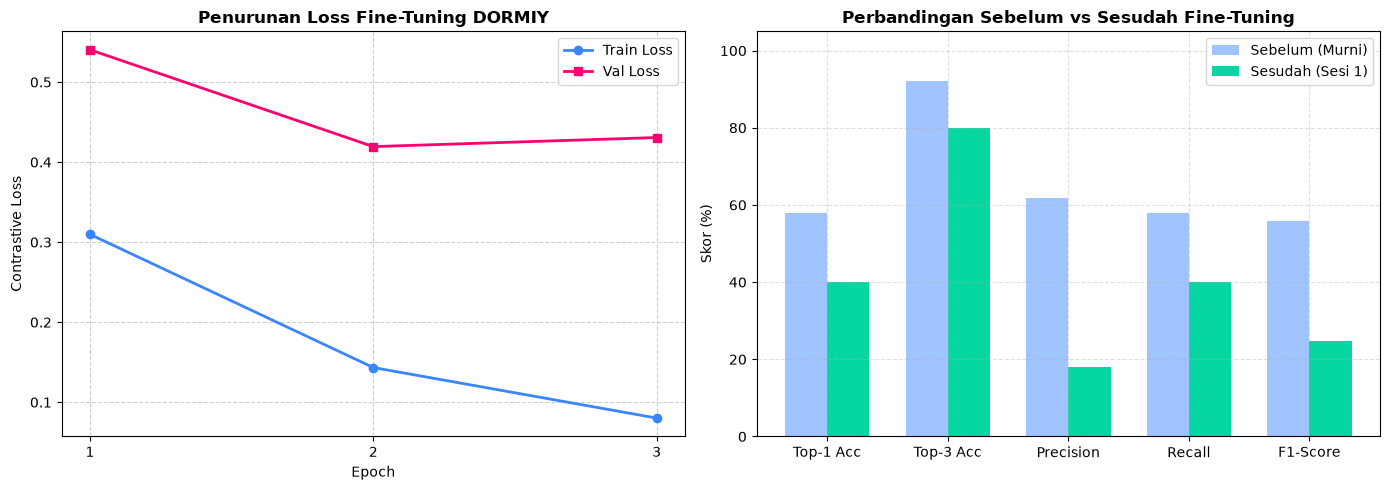

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


💾 Model hasil training Sesi 1 berhasil disimpan di: experiment_results/sesi_1_dormiy\model_clip_dormiy_sesi1/


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Plot Loss Penurunan
axes[0].plot(history['epoch'], history['train_loss'], label='Train Loss', marker='o', color='#3a86ff', linewidth=2)
axes[0].plot(history['epoch'], history['val_loss'], label='Val Loss', marker='s', color='#ff006e', linewidth=2)
axes[0].set_title('Penurunan Loss Fine-Tuning DORMIY', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Contrastive Loss')
axes[0].set_xticks(history['epoch'])
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# 2. Plot Perbandingan Sebelum vs Sesudah Fine-Tuning (Top-1, Top-3, F1)
labels = ['Top-1 Acc', 'Top-3 Acc', 'Precision', 'Recall', 'F1-Score']
before_vals = [base_top1, base_top3, base_prec, base_rec, base_f1]
after_vals = [history['top1_acc'][-1], history['top3_acc'][-1], history['precision'][-1], history['recall'][-1], history['f1_score'][-1]]

x = np.arange(len(labels))
width = 0.35

axes[1].bar(x - width/2, before_vals, width, label='Sebelum (Murni)', color='#a0c4ff')
axes[1].bar(x + width/2, after_vals, width, label='Sesudah (Sesi 1)', color='#06d6a0')
axes[1].set_ylabel('Skor (%)')
axes[1].set_title('Perbandingan Sebelum vs Sesudah Fine-Tuning', fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
chart_path = os.path.join(EXPERIMENT_DIR, "perbandingan_sesi_1.png")
plt.savefig(chart_path, dpi=200)
plt.show()

# Simpan Bobot Model Fine-Tuned Sesi 1
MODEL_SAVE_DIR = os.path.join(EXPERIMENT_DIR, "model_clip_dormiy_sesi1")
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)
model.save_pretrained(MODEL_SAVE_DIR)
processor.save_pretrained(MODEL_SAVE_DIR)
print(f"\n💾 Model hasil training Sesi 1 berhasil disimpan di: {MODEL_SAVE_DIR}/")